# Preprocessing QC — ICA

QC checks for the filtering + ICA pipeline (`src/preprocessing.py`):

1. Subject 1: PSD before vs. after ICA.
2. Subject 1: first 10 s of the signal before vs. after ICA, on Fp1, Fz, Cz, T7.
3. Number of ICA components rejected per subject, across all subjects.

All figures are saved to `results/figures/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from loading import load_subject
from preprocessing import filter_raw, fit_ica, load_cleaned_raw

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Validated two-color categorical pair (dataviz skill, references/palette.md slots 1-2)
COLOR_BEFORE = "#2a78d6"  # before ICA
COLOR_AFTER = "#eb6834"   # after ICA

## Subject 1: before vs. after ICA

"After" is loaded from the saved checkpoint (`data/processed/sub01_raw.fif`, written by
`save_cleaned_raw`) rather than recomputed, per the project's checkpoint convention.
"Before" is the same 1-8 Hz analysis-band filtering, just without ICA applied, so the
only difference between the two is the ICA cleaning step.

In [2]:
raw1 = load_subject(1, RAW_DIR)
raw_hp1 = filter_raw(raw1, "ica_prep")
raw_before1 = filter_raw(raw1, "analysis")
ica1 = fit_ica(raw_hp1, n_components=20)
raw_after1 = load_cleaned_raw(1, PROCESSED_DIR)

print(f"Subject 1: {len(ica1.exclude)} component(s) excluded: {list(ica1.exclude)}")

Creating RawArray with float64 data, n_channels=64, n_times=591672
    Range : 0 ... 591671 =      0.000 ...  4622.430 secs
Ready.
Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Filter length: 423 samples (3.305 s)

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 8 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuat

### Power spectral density, before vs. after ICA

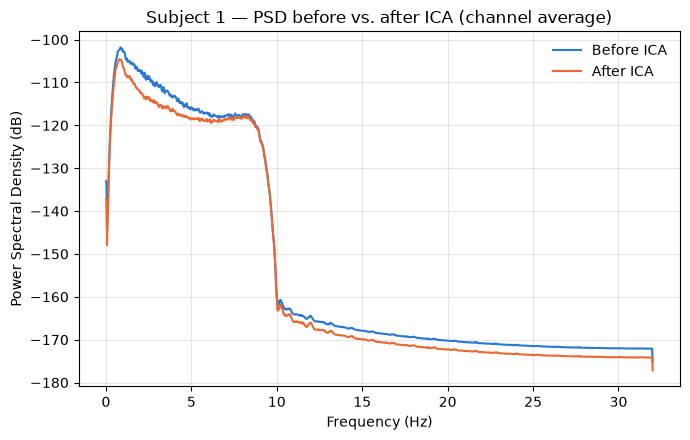

In [3]:
def _avg_psd_db(raw, fmax):
    spectrum = raw.compute_psd(fmax=fmax, verbose=False)
    psds, freqs = spectrum.get_data(return_freqs=True)
    return freqs, 10 * np.log10(psds.mean(axis=0))


fmax = raw_after1.info["sfreq"] / 2
freqs_before, psd_before = _avg_psd_db(raw_before1, fmax)
freqs_after, psd_after = _avg_psd_db(raw_after1, fmax)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(freqs_before, psd_before, color=COLOR_BEFORE, lw=1.5, label="Before ICA")
ax.plot(freqs_after, psd_after, color=COLOR_AFTER, lw=1.5, label="After ICA")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Power Spectral Density (dB)")
ax.set_title("Subject 1 — PSD before vs. after ICA (channel average)")
ax.grid(True, alpha=0.3)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "sub01_psd_before_after_ica.png", dpi=150)
plt.show()

### First 10 seconds, before vs. after ICA (Fp1, Fz, Cz, T7)

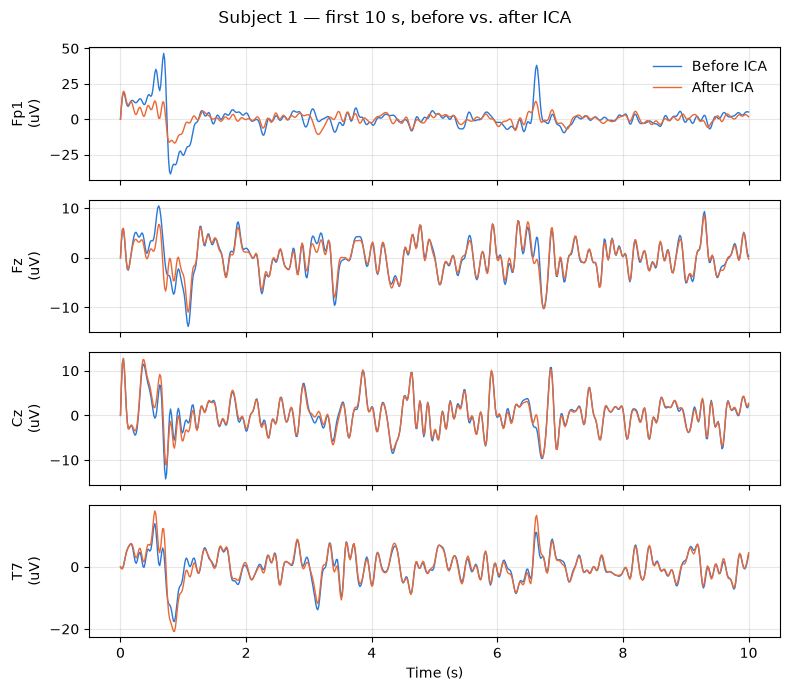

In [4]:
channels = ["Fp1", "Fz", "Cz", "T7"]
tmax = 10.0

before_seg = raw_before1.copy().pick(channels).crop(tmin=0, tmax=tmax)
after_seg = raw_after1.copy().pick(channels).crop(tmin=0, tmax=tmax)

before_uv = before_seg.get_data() * 1e6
after_uv = after_seg.get_data() * 1e6
times = before_seg.times

fig, axes = plt.subplots(len(channels), 1, figsize=(8, 7), sharex=True)
for i, (ax, ch) in enumerate(zip(axes, channels)):
    ax.plot(times, before_uv[i], color=COLOR_BEFORE, lw=1.0, label="Before ICA")
    ax.plot(times, after_uv[i], color=COLOR_AFTER, lw=1.0, label="After ICA")
    ax.set_ylabel(f"{ch}\n(uV)")
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Time (s)")
axes[0].legend(frameon=False, loc="upper right")
fig.suptitle("Subject 1 — first 10 s, before vs. after ICA")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "sub01_timeseries_before_after_ica.png", dpi=150)
plt.show()

## ICA components rejected per subject, across all subjects

Re-fits ICA (on the `ica_prep` high-pass Raw) for every subject found in `data/raw/`
to tally how many EOG-related components `fit_ica` flagged. Subject 1's result from
above is reused rather than recomputed.

In [5]:
subject_files = sorted(RAW_DIR.glob("S*.mat"))
rows = []
for f in subject_files:
    subject_num = int(f.stem.lstrip("S"))
    if subject_num == 1:
        excluded = list(ica1.exclude)
    else:
        raw = load_subject(subject_num, RAW_DIR)
        raw_hp = filter_raw(raw, "ica_prep")
        ica = fit_ica(raw_hp, n_components=20)
        excluded = list(ica.exclude)
    rows.append({"subject": f"S{subject_num}", "n_components_excluded": len(excluded),
                 "excluded_indices": excluded})

summary = pd.DataFrame(rows).sort_values("subject", key=lambda s: s.str.lstrip("S").astype(int))
summary = summary.reset_index(drop=True)
print(summary.to_string(index=False))
print(f"\nMean excluded components across {len(summary)} subjects: "
      f"{summary['n_components_excluded'].mean():.2f}")

Creating RawArray with float64 data, n_channels=64, n_times=591672
    Range : 0 ... 591671 =      0.000 ...  4622.430 secs
Ready.
Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Filter length: 423 samples (3.305 s)

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Fitting ICA to data using 64 channels (please be patient, this may take a while)
Selecting by number: 20 components
Fitting ICA took 5.7s.
Using EOG channel: Fp1
... filtering ICA sources
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and r